In [1]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.compiler import transpile
from collections import Counter
from collections import Counter
import bluequbit

/Users/qmlwizard/Developer/bluequbit-hackathon/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


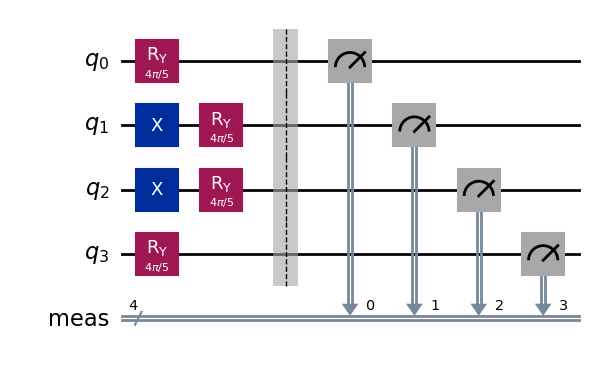

In [13]:
## Problem 1
qc = QuantumCircuit.from_qasm_file('qasm-files/P1.qasm')
qc.measure_all()
qc.draw(output='mpl')

In [14]:
# Simulate with statevector
sim = Aer.get_backend('statevector_simulator')
qc = transpile(qc, sim)
result = sim.run(qc).result()
statevector = result.get_statevector()

# Print top measurement probabilities
import numpy as np
probabilities = np.abs(statevector)**2
top_index = np.argmax(probabilities)
top_bitstring = format(top_index, f'0{qc.num_qubits}b')

print("🔍 Peak Bitstring:", top_bitstring)
print("Peak Probability:", probabilities[top_index])

🔍 Peak Bitstring: 1000
Peak Probability: 0.9999999999999998




In [15]:
## Problem 2
qc = QuantumCircuit.from_qasm_file('qasm-files/P2.qasm')
qc.measure_all()
qc.draw(output='mpl')

In [16]:
# Simulate with statevector
sim = Aer.get_backend('statevector_simulator')
qc = transpile(qc, sim)
result = sim.run(qc).result()
statevector = result.get_statevector()

# Print top measurement probabilities
import numpy as np
probabilities = np.abs(statevector)**2
top_index = np.argmax(probabilities)
top_bitstring = format(top_index, f'0{qc.num_qubits}b')

print("🔍 Peak Bitstring:", top_bitstring)
print("Peak Probability:", probabilities[top_index])

🔍 Peak Bitstring: 1100101100111101001010000100
Peak Probability: 0.9999999999999998


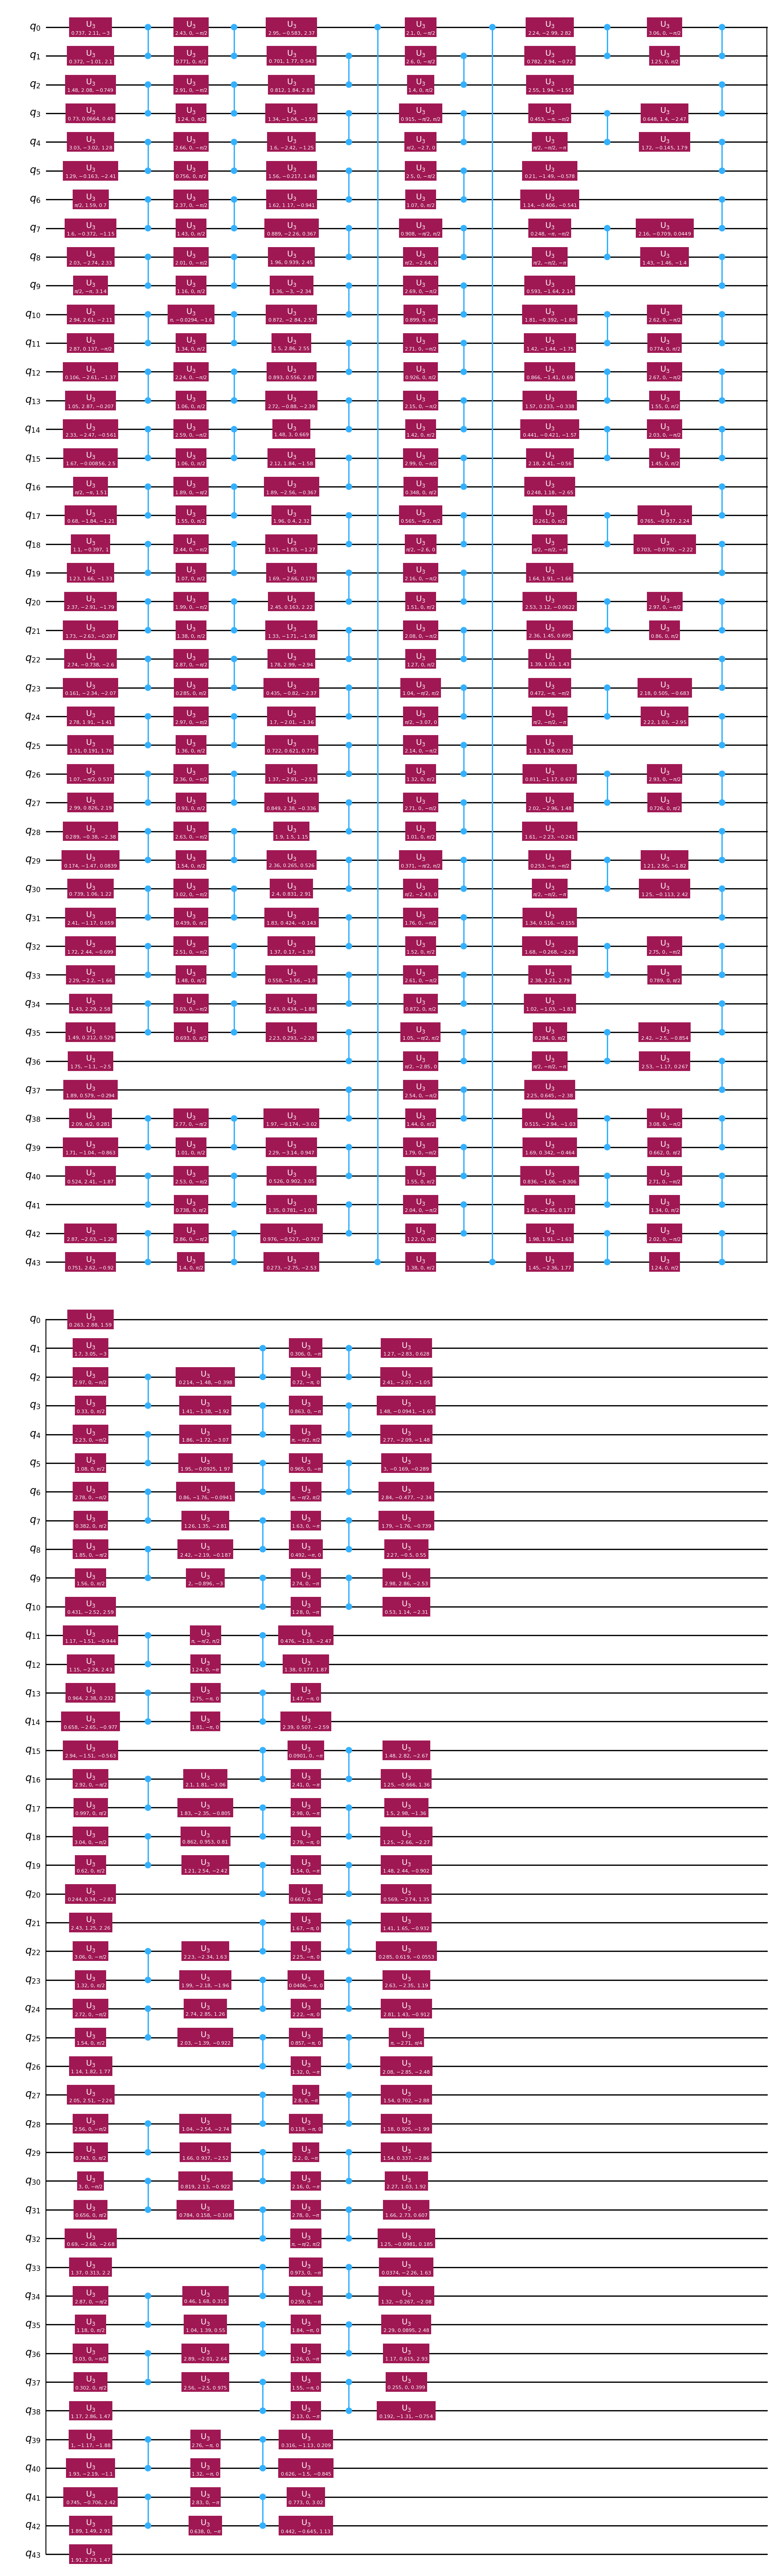

In [6]:
## Problem 3
qc = QuantumCircuit.from_qasm_file('qasm-files/P3.qasm')
#qc.measure_all()
qc.draw(output='mpl')

In [9]:
from qiskit import QuantumCircuit
from qiskit.compiler import transpile
import quimb.tensor as qtn

# --- Load and transpile circuit ---
#qc = QuantumCircuit.from_qasm_file("your_circuit.qasm")
qc = transpile(qc, basis_gates=['rx', 'rz', 'cx'], optimization_level=3)

# --- Create Quimb Circuit ---
circ = qtn.Circuit(N=qc.num_qubits)

# --- Map Qiskit gates to Quimb gates ---
for instr in qc.data:
    name = instr.operation.name
    qubits = [qc.qubits.index(q) for q in instr.qubits]

    if name == "rx":
        theta = float(instr.operation.params[0])
        circ.apply_gate("Rx", theta, qubits[0])
    elif name == "rz":
        theta = float(instr.operation.params[0])
        circ.apply_gate("Rz", theta, qubits[0])
    elif name == "cx":
        circ.apply_gate("CNOT", *qubits)
    elif name == "barrier":
        continue
    else:
        print(f"⚠️ Skipping unsupported gate: {name}")

# --- Contract the circuit to get the full state (TensorNetworkGenVector) ---
C = circ.psi(optimize='cotengra-hyper')  # ⚠️ this returns the state vector tensor

# --- Sample one bitstring from the state ---
peak_bs = circ.sample(C)
print("🔍 Estimated Peak Bitstring:", peak_bs)


TypeError: 'TensorNetworkGenVector' object is not callable